In [2]:
import joblib
import numpy as np
import pandas as pd
from equation import equations
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder , LabelEncoder , OneHotEncoder


In [3]:
equat = equations()

In [4]:
csv = equat.csv_path("Ai_student_impact.csv")
data = pd.read_csv(csv , encoding="windows-1252")
data.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [5]:
data.columns

Index(['Student_ID', 'Major_Category', 'Year_of_Study', 'Pre_Semester_GPA',
       'Weekly_GenAI_Hours', 'Primary_Use_Case', 'Prompt_Engineering_Skill',
       'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours',
       'Perceived_AI_Dependency', 'Institutional_Policy',
       'Anxiety_Level_During_Exams', 'Post_Semester_GPA',
       'Skill_Retention_Score', 'Burnout_Risk_Level'],
      dtype='object')

In [6]:
data = data.drop('Student_ID' , axis = 1 )

In [7]:
data.isna().sum()

Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
x = data.drop("Burnout_Risk_Level", axis=1)
y = data["Burnout_Risk_Level"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [10]:
x_train.nunique()

Major_Category                   5
Year_of_Study                    5
Pre_Semester_GPA              2351
Weekly_GenAI_Hours            3439
Primary_Use_Case                 5
Prompt_Engineering_Skill         3
Tool_Diversity                   5
Paid_Subscription                2
Traditional_Study_Hours       2486
Perceived_AI_Dependency         10
Institutional_Policy             3
Anxiety_Level_During_Exams      10
Post_Semester_GPA             2233
Skill_Retention_Score         5734
dtype: int64

In [11]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40000 entries, 39087 to 15795
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Major_Category              40000 non-null  object 
 1   Year_of_Study               40000 non-null  object 
 2   Pre_Semester_GPA            40000 non-null  float64
 3   Weekly_GenAI_Hours          40000 non-null  float64
 4   Primary_Use_Case            40000 non-null  object 
 5   Prompt_Engineering_Skill    40000 non-null  object 
 6   Tool_Diversity              40000 non-null  int64  
 7   Paid_Subscription           40000 non-null  bool   
 8   Traditional_Study_Hours     40000 non-null  float64
 9   Perceived_AI_Dependency     40000 non-null  int64  
 10  Institutional_Policy        40000 non-null  object 
 11  Anxiety_Level_During_Exams  40000 non-null  int64  
 12  Post_Semester_GPA           40000 non-null  float64
 13  Skill_Retention_Score       4000

In [12]:
y_train

39087    Medium
30893       Low
45278    Medium
16398       Low
13653    Medium
          ...  
11284       Low
44732       Low
38158      High
860      Medium
15795    Medium
Name: Burnout_Risk_Level, Length: 40000, dtype: object

In [13]:
bin_obj = ['Paid_Subscription']
columns_numeric = x_train.select_dtypes(include=["int64", "float64"]).columns
obj_col = [col for col in x_train.columns if col not in columns_numeric and col not in bin_obj]

In [14]:
x_train[columns_numeric] = equat.ALLOWED_RANGE(x_train[columns_numeric])
x_test[columns_numeric] = equat.ALLOWED_RANGE(x_test[columns_numeric] , test=True)

In [15]:
LE = LabelEncoder()
pre = ColumnTransformer(
    transformers=[
        ('bin_feat' , OneHotEncoder(drop='if_binary' , sparse_output=False , handle_unknown='ignore') , bin_obj) , 
        ('obj_feat' , TargetEncoder(smooth="auto", cv=5) , obj_col ) , 
        ('num_feat' , StandardScaler() , columns_numeric),
    ] , remainder='passthrough'
).set_output(transform="pandas")

In [16]:
y_train = LE.fit_transform(y_train)
y_test = LE.transform(y_test)

x_train = pre.fit_transform(x_train , y_train)
x_test = pre.transform(x_test)

In [17]:
Clean_data = {
    'x_train' : x_train,
    'x_test' : x_test,
    'y_train' : y_train,
    'y_test' : y_test,
}
joblib.dump(Clean_data, "processed_data.joblib")

['processed_data.joblib']

<Axes: ylabel='Count'>

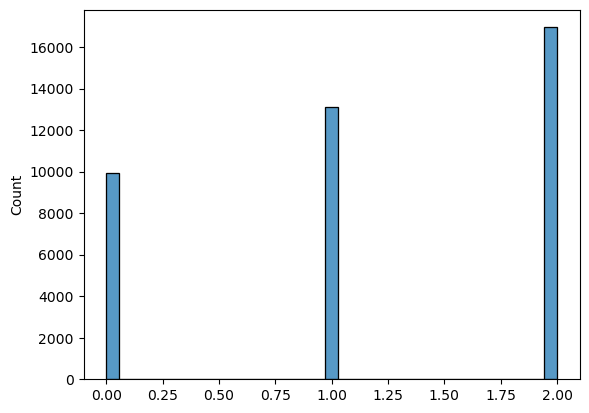

In [18]:
import seaborn as sns
sns.histplot(y_train)

***Because it is mildly imbalanced, average='macro' is still the best and most honest setting for your F1-score. It will treat your 10k class with the exact same importance as your 17k class, ensuring your model is truly performing well across all burnout levels***

***^^^FOR DECISION_TREE (F1_SCORE)^^^***